# EDA : Data visualisation and analysis 


**Import libraries**


In [73]:
import numpy as np 
import pandas as pd
import random 
import os  
import torch 
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnchoredText


In [74]:
plt.style.use('ggplot')

def seed_set(seed=50):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
seed_set()

In [75]:
from xyz2graph import MolGraph, to_networkx_graph, to_plotly_figure
from plotly.offline import init_notebook_mode, iplot
import networkx as nx


In [109]:
# Folder of the dataset (NOT the csv file)
DATA_DIR = r'C:\Users\pc\Downloads\champs-scalar-coupling'
CSV_PATH = os.path.join(DATA_DIR, 'structures.csv')
XYZ_DIR  = os.path.join(DATA_DIR, 'structures')  
COUPLING_DIR  = os.path.join(DATA_DIR , 'scalar_coupling_contributions') 

In [77]:
init_notebook_mode(connected=True)
structures = pd.read_csv(CSV_PATH)
mol_names = structures.molecule_name.unique()

In [78]:
print(structures.head())


      molecule_name  atom_index atom         x         y         z
0  dsgdb9nsd_000001           0    C -0.012698  1.085804  0.008001
1  dsgdb9nsd_000001           1    H  0.002150 -0.006031  0.001976
2  dsgdb9nsd_000001           2    H  1.011731  1.463751  0.000277
3  dsgdb9nsd_000001           3    H -0.540815  1.447527 -0.876644
4  dsgdb9nsd_000001           4    H -0.523814  1.437933  0.906397


In [79]:
structures.head(3).to_dict(orient='records')

[{'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 0,
  'atom': 'C',
  'x': -0.0126981359,
  'y': 1.0858041578,
  'z': 0.0080009957999999},
 {'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 1,
  'atom': 'H',
  'x': 0.002150416,
  'y': -0.0060313176,
  'z': 0.0019761204},
 {'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 2,
  'atom': 'H',
  'x': 1.0117308433,
  'y': 1.4637511618,
  'z': 0.0002765748}]

In [80]:
molecule_atoms = [
    {
        'molecule_name': 'dsgdb9nsd_000001',
        'atom_index': 0,
        'atom': 'C',
        'x': -0.0126981359,
        'y': 1.0858041578,
        'z': 0.0080009957999999,
    },
    {
        'molecule_name': 'dsgdb9nsd_000001',
        'atom_index': 1,
        'atom': 'H',
        'x': 0.002150416,
        'y': -0.0060313176,
        'z': 0.0019761204,
    },
    {
        'molecule_name': 'dsgdb9nsd_000001',
        'atom_index': 2,
        'atom': 'H',
        'x': 1.0117308433,
        'y': 1.4637511618,
        'z': 0.0002765748,
    },
]

molecule_atoms

[{'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 0,
  'atom': 'C',
  'x': -0.0126981359,
  'y': 1.0858041578,
  'z': 0.0080009957999999},
 {'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 1,
  'atom': 'H',
  'x': 0.002150416,
  'y': -0.0060313176,
  'z': 0.0019761204},
 {'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 2,
  'atom': 'H',
  'x': 1.0117308433,
  'y': 1.4637511618,
  'z': 0.0002765748}]

In [81]:
mol_names = structures.molecule_name.unique()

In [82]:
def draw_random_mol():
    mol_name = random.choice(mol_names)
    mg = MolGraph()
    mg.read_xyz(os.path.join(XYZ_DIR, f'{mol_name}.xyz'))
    fig = to_plotly_figure(mg)
    iplot(fig)

def draw_random_networx_graph():
    mol_name = random.choice(mol_names)
    mg = MolGraph()
    mg.read_xyz(os.path.join(XYZ_DIR, f'{mol_name}.xyz'))
    G = to_networkx_graph(mg)
    print('Nodes:')
    print(list(G.nodes(data=True))[:5])
    print('Edges:')
    print(list(G.edges(data=True))[:5])
    nx.draw(G, with_labels=True)

In [83]:
draw_random_mol()

C:\Users\pc\AppData\Local\Temp\ipykernel_12328\2953702703.py:5: DeprecationWarning: to_plotly_figure is deprecated and will be removed in version 4.0.0. Use MolGraph.to_plotly() instead.
  fig = to_plotly_figure(mg)


In [84]:
draw_random_mol()

C:\Users\pc\AppData\Local\Temp\ipykernel_12328\2953702703.py:5: DeprecationWarning: to_plotly_figure is deprecated and will be removed in version 4.0.0. Use MolGraph.to_plotly() instead.
  fig = to_plotly_figure(mg)


C:\Users\pc\AppData\Local\Temp\ipykernel_12328\2953702703.py:12: DeprecationWarning: to_networkx_graph is deprecated and will be removed in version 4.0.0. Use MolGraph.to_networkx() instead.
  G = to_networkx_graph(mg)


Nodes:
[(0, {'element': 'N', 'xyz': (0.2654798939, -1.2136135244, 0.564796426)}), (1, {'element': 'C', 'xyz': (0.1420400301, -0.0935578448, 0.3085994399)}), (2, {'element': 'C', 'xyz': (-0.0237309669, 1.3329118592, 0.0142835989)}), (3, {'element': 'C', 'xyz': (-0.8366184774, 1.9869439674, 1.1653474151)}), (4, {'element': 'O', 'xyz': (-1.3013292817, 3.2708547961, 0.839168058)})]
Edges:
[(0, 1, {'length': np.float64(1.15559)}), (1, 2, {'length': np.float64(1.46592)}), (2, 3, {'length': np.float64(1.55354)}), (2, 8, {'length': np.float64(1.52174)}), (2, 9, {'length': np.float64(1.10019)})]


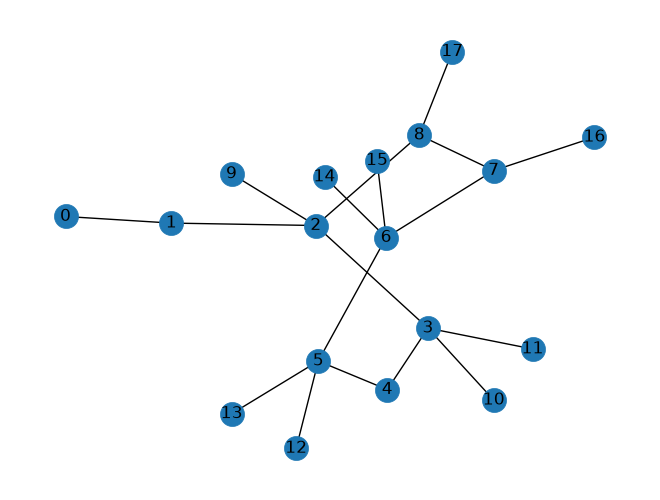

In [85]:
draw_random_networx_graph()

In [86]:
from matplotlib.animation import ArtistAnimation
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from IPython.display import Image, display 
import seaborn as sns 



In [87]:
TRAIN_FILE = r'C:\Users\pc\Downloads\champs-scalar-coupling\train.csv'
train_df = pd.read_csv(TRAIN_FILE)
train_df.head()


,id,molecule_name,atom_index_0,atom_index_1,type,scalar_coupling_constant
0,0,dsgdb9nsd_000001,1,0,1JHC,84.8076
1,1,dsgdb9nsd_000001,1,2,2JHH,-11.2570
2,2,dsgdb9nsd_000001,1,3,2JHH,-11.2548
3,3,dsgdb9nsd_000001,1,4,2JHH,-11.2543
4,4,dsgdb9nsd_000001,2,0,1JHC,84.8074


**To compare molecules fairly, we normalize each 1JHN pair: the H atom is translated to (0,0,0) and the molecule is rotated so that N lies at (1,0,0). This removes the effect of position and orientation in space, which do not influence the coupling constant, leaving only the internal geometry (distances and angles) that actually matters. It also lets us overlay molecules in the same frame and see how N's other neighbors are arranged."**

In [88]:
print(train_df.shape)                 # l-original: (4659076, 6)
print(train_df['type'].unique())      # l-original: 8 types

(4659076, 6)
['1JHC' '2JHH' '1JHN' '2JHN' '2JHC' '3JHH' '3JHC' '3JHN']


In [89]:

TEST_PATH = os.path.join(DATA_DIR, 'test.csv')
test_df = pd.read_csv(TEST_PATH)

In [90]:
print(test_df.shape)
print(test_df['type'].unique())


(2505190, 5)
['2JHC' '1JHC' '3JHH' '2JHH' '3JHC' '3JHN' '1JHN' '2JHN']


        train    test  train_%  test_%
type                                  
3JHC  1511207  811351    32.44   32.39
2JHC  1140867  613087    24.49   24.47
1JHC   709133  380968    15.22   15.21
3JHH   590529  317582    12.67   12.68
2JHH   377988  203201     8.11    8.11
3JHN   166613   90459     3.58    3.61
2JHN   119059   64647     2.56    2.58
1JHN    43680   23895     0.94    0.95


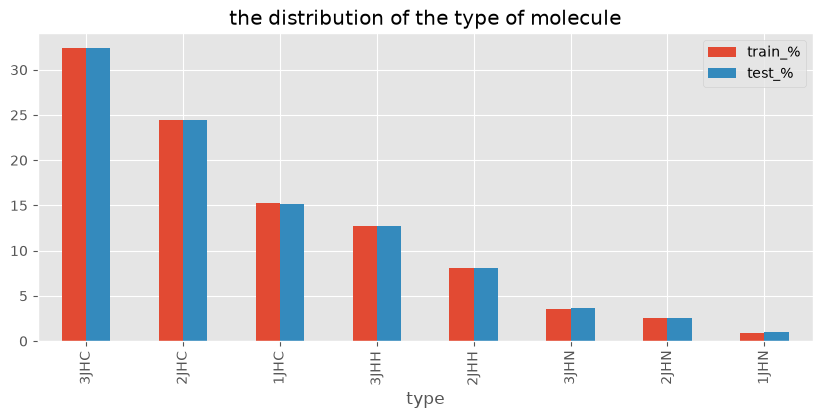

In [91]:
counts = pd.DataFrame({
    'train': train_df['type'].value_counts(),
    'test': test_df['type'].value_counts()
})
counts['train_%'] = (counts['train'] / counts['train'].sum() * 100).round(2)
counts['test_%'] = (counts['test'] / counts['test'].sum() * 100).round(2)
print(counts)
counts[['train_%', 'test_%']].plot(kind='bar', figsize=(10, 4))
plt.title('the distribution of the type of molecule')
plt.show()

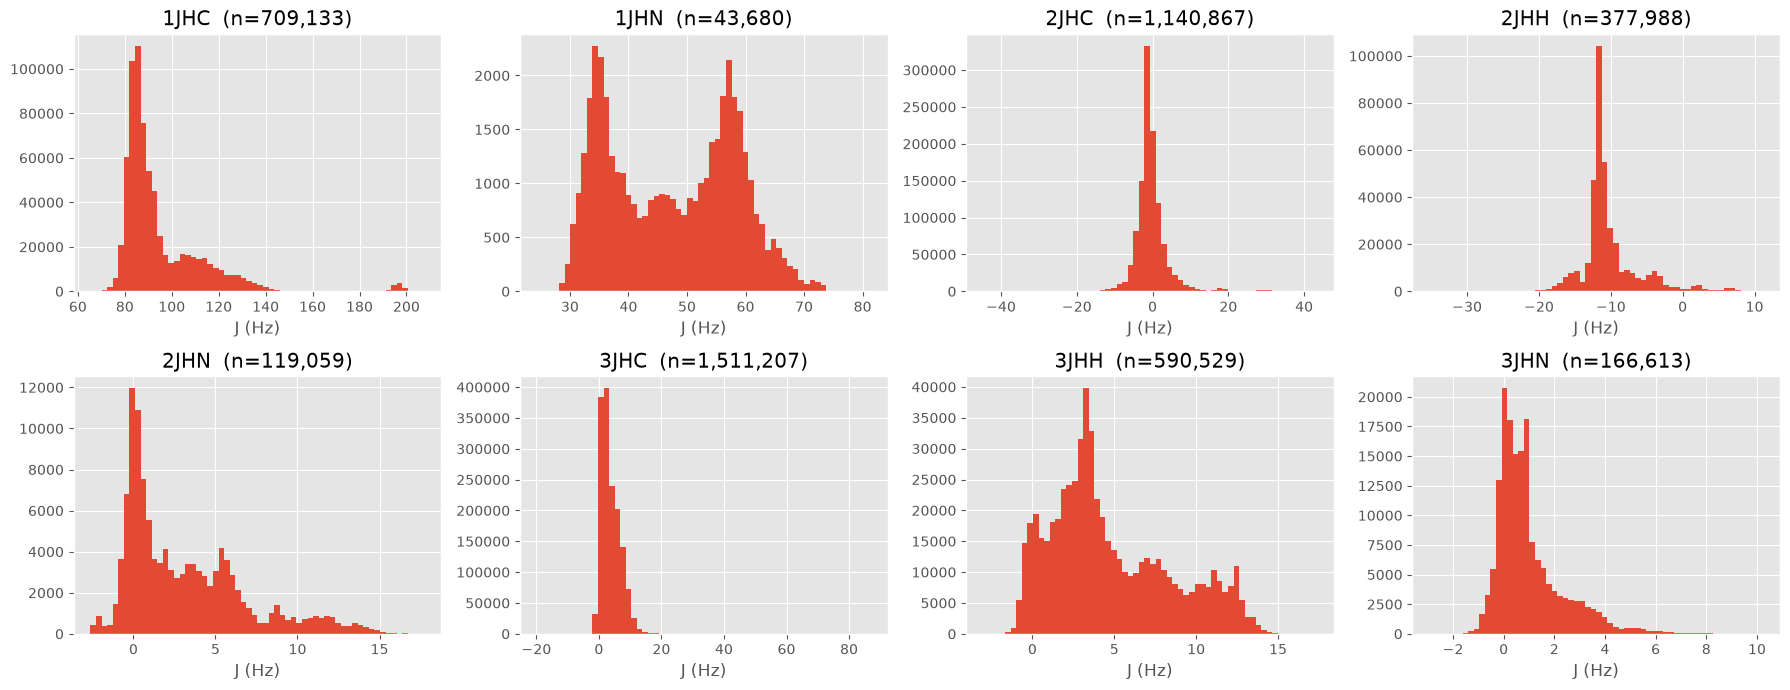

        count   mean    std    min     max
type                                      
1JHC   709133  94.97  18.29  65.35  207.71
1JHN    43680  47.49  10.90  24.32   81.40
2JHC  1140867  -0.27   4.52 -44.76   43.41
2JHH   377988 -10.28   3.98 -35.27   11.22
2JHN   119059   3.13   3.68  -2.62   17.74
3JHC  1511207   3.69   3.08 -19.89   86.96
3JHH   590529   4.77   3.71  -3.02   17.38
3JHN   166613   0.99   1.32  -2.94   10.25


In [92]:
types = sorted(train_df['type'].unique())
fig, axes = plt.subplots(2, 4, figsize=(18, 7))

for ax, t in zip(axes.ravel(), types):
    d = train_df.loc[train_df['type'] == t, 'scalar_coupling_constant']
    ax.hist(d, bins=60)
    ax.set_title(f'{t}  (n={len(d):,})')
    ax.set_xlabel('J (Hz)')

plt.tight_layout()
plt.show()

# jadwal rqmi: mean, std, min, max
print(train_df.groupby('type')['scalar_coupling_constant']
      .agg(['count', 'mean', 'std', 'min', 'max']).round(2))

In [106]:




def add_coords(df, idx):
    s = structures.rename(columns={
        'atom_index': f'atom_index_{idx}',
        'atom': f'atom_{idx}',
        'x': f'x_{idx}', 'y': f'y_{idx}', 'z': f'z_{idx}'})
    return df.merge(s, on=['molecule_name', f'atom_index_{idx}'], how='left')
    
train_df = add_coords(train_df, 0)
train_df  = add_coords(train_df, 1)
test_df = add_coords(test_df, 0)
test_df = add_coords(test_df, 1)

for df in (train_df, test_df):
    df['dist'] = np.sqrt((df['x_0'] - df['x_1'])**2 +
                         (df['y_0'] - df['y_1'])**2 +
                         (df['z_0'] - df['z_1'])**2).astype('float32')



In [108]:
train_df.head()

,id,molecule_name,atom_index_0,atom_index_1,type,scalar_coupling_constant,atom_0,x_0,y_0,z_0,atom_1,x_1,y_1,z_1,dist
0,0,dsgdb9nsd_000001,1,0,1JHC,84.8076,H,0.002150,-0.006031,0.001976,C,-0.012698,1.085804,0.008001,1.091953
1,1,dsgdb9nsd_000001,1,2,2JHH,-11.2570,H,0.002150,-0.006031,0.001976,H,1.011731,1.463751,0.000277,1.783120
2,2,dsgdb9nsd_000001,1,3,2JHH,-11.2548,H,0.002150,-0.006031,0.001976,H,-0.540815,1.447527,-0.876644,1.783147
3,3,dsgdb9nsd_000001,1,4,2JHH,-11.2543,H,0.002150,-0.006031,0.001976,H,-0.523814,1.437933,0.906397,1.783157
4,4,dsgdb9nsd_000001,2,0,1JHC,84.8074,H,1.011731,1.463751,0.000277,C,-0.012698,1.085804,0.008001,1.091952


In [ ]:
train_df['dist'].isna().sum().astype('float32')

np.int64(0)

1JHC -0.705
1JHN -0.868
2JHC 0.287
2JHH 0.529
2JHN -0.161
3JHC 0.32
3JHH 0.264
3JHN 0.272


C:\Users\pc\AppData\Local\Temp\ipykernel_12328\916620396.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g['dist'].corr(g['scalar_coupling_constant']))


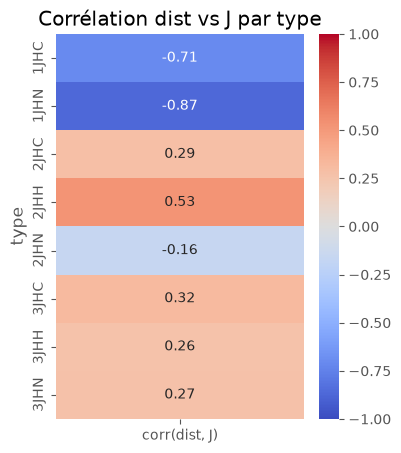

In [120]:
for t, g in train_df.groupby('type'):
    print(t, round(g['dist'].corr(g['scalar_coupling_constant']), 3))

corr_by_type = (train_df.groupby('type')
                .apply(lambda g: g['dist'].corr(g['scalar_coupling_constant']))
                .rename('corr(dist, J)')
                .to_frame())
plt.figure(figsize = (4 , 5))
sns.heatmap(corr_by_type  , annot =True , fmt = '.2f' , cmap ='coolwarm' ,vmin = -1 ,vmax =  1 ) 
plt.title('Corrélation dist vs J par type')
plt.show()



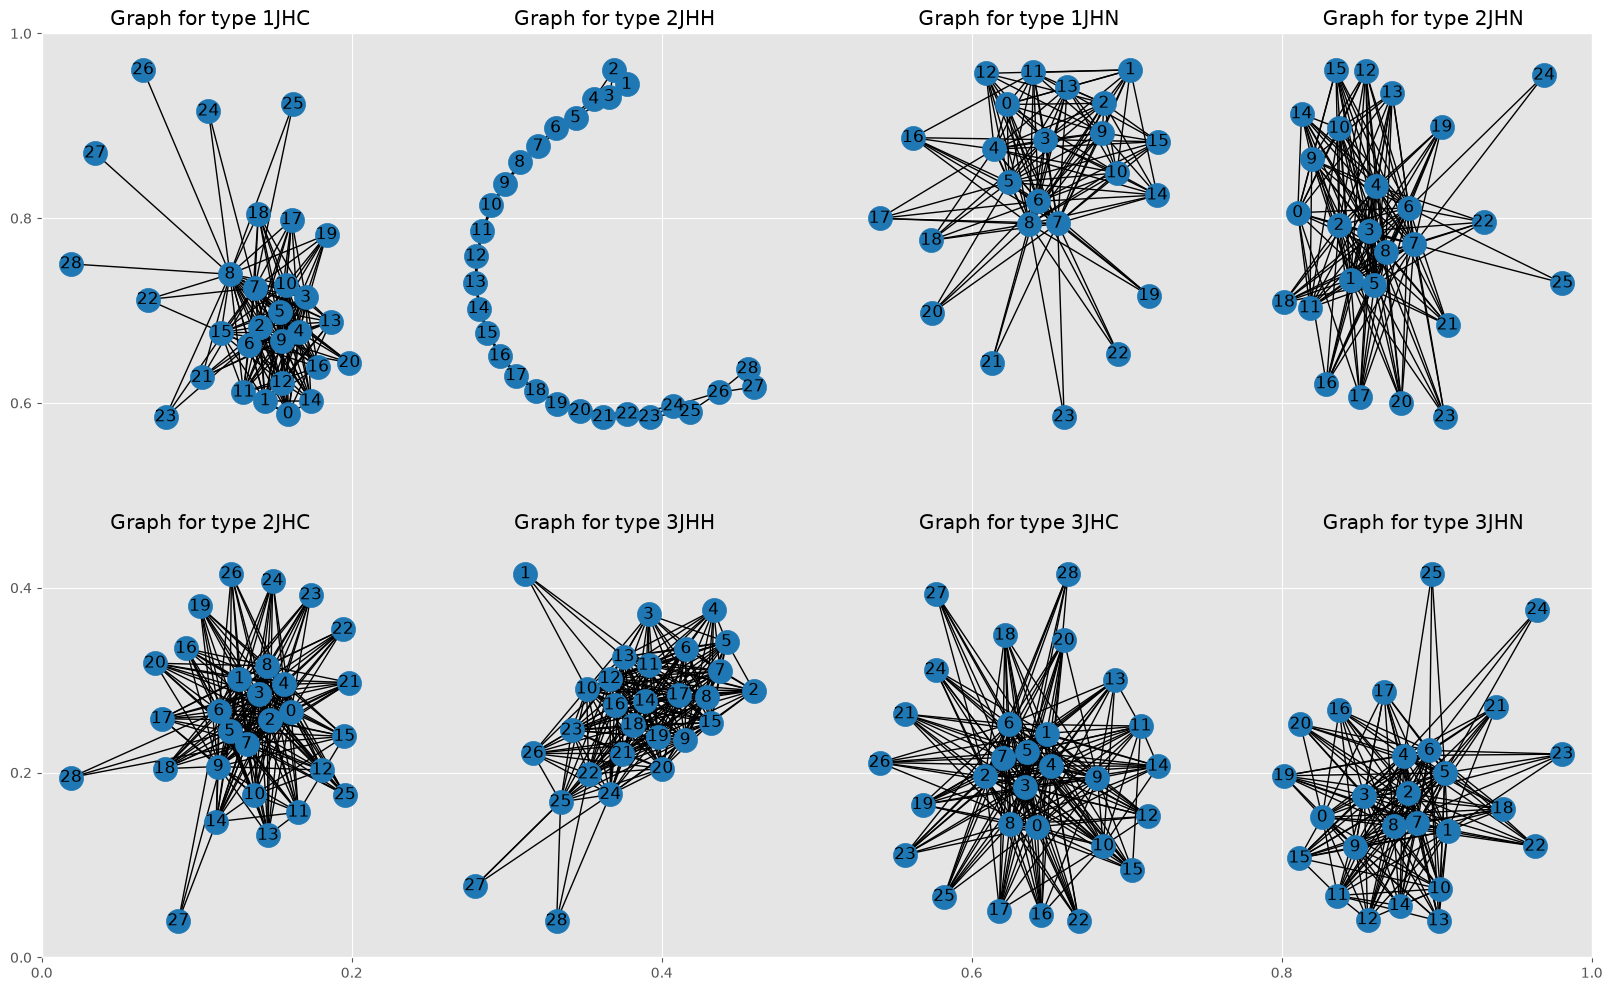

In [121]:
fig, ax = plt.subplots(figsize = (20, 12))
for i, t in enumerate(train_df['type'].unique()):
    train_type = train_df.loc[train_df['type'] == t]
    G = nx.from_pandas_edgelist(train_type, 'atom_index_0', 'atom_index_1', ['scalar_coupling_constant'])
    plt.subplot(2, 4, i + 1);
    nx.draw(G, with_labels=True);
    plt.title(f'Graph for type {t}')

Better network graphs
But there is a little problem: as we saw earlier, there are atoms which are very rare, as a result graphs will be skewed due to them. Now I'll drop atoms for each type which are present in less then 1% of connectionsµ

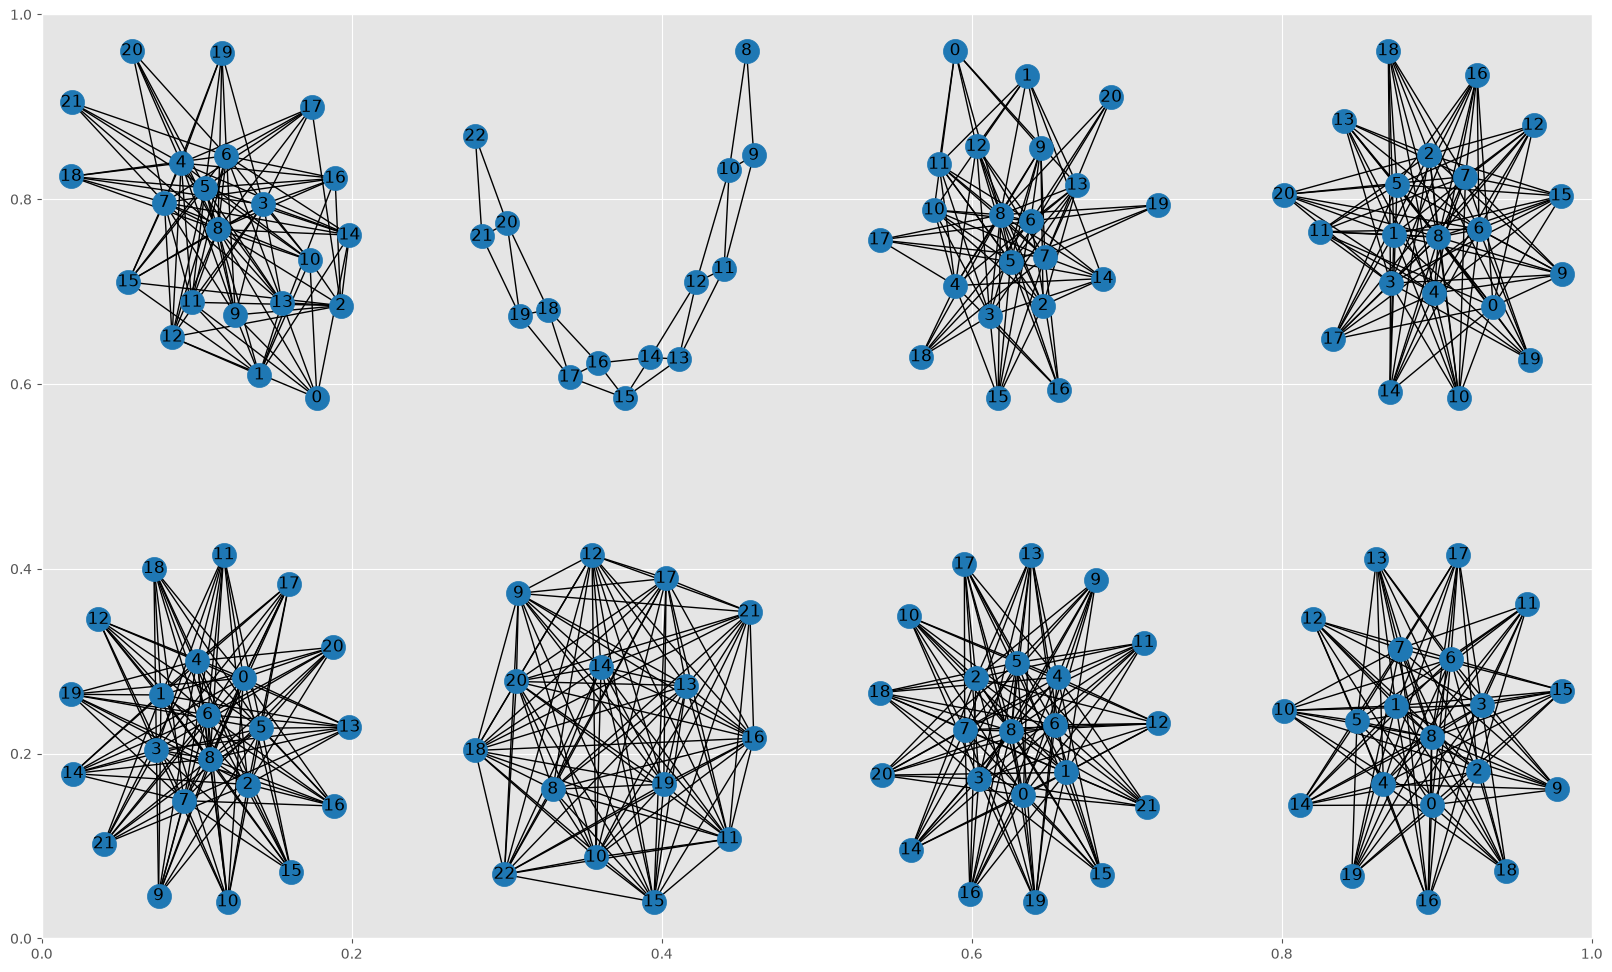

In [122]:
fig, ax = plt.subplots(figsize = (20, 12))
for i, t in enumerate(train_df['type'].unique()):
    train_type = train_df.loc[train_df['type'] == t]
    bad_atoms_0 = list(train_type['atom_index_0'].value_counts(normalize=True)[train_type['atom_index_0'].value_counts(normalize=True) < 0.01].index)
    bad_atoms_1 = list(train_type['atom_index_1'].value_counts(normalize=True)[train_type['atom_index_1'].value_counts(normalize=True) < 0.01].index)
    bad_atoms = list(set(bad_atoms_0 + bad_atoms_1))
    train_type = train_type.loc[(train_type['atom_index_0'].isin(bad_atoms_0) == False) & (train_type['atom_index_1'].isin(bad_atoms_1) == False)]
    G = nx.from_pandas_edgelist(train_type, 'atom_index_0', 'atom_index_1', ['scalar_coupling_constant'])
    plt.subplot(2, 4, i + 1);
    nx.draw(G, with_labels=True);

In [111]:
COUPLING_DIR = os.path.join(DATA_DIR , 'scalar_coupling_contributions.csv')

In [112]:
scalar_coupling_constants = pd.read_csv(COUPLING_DIR)


MovieWriter imagemagick unavailable; using Pillow instead.


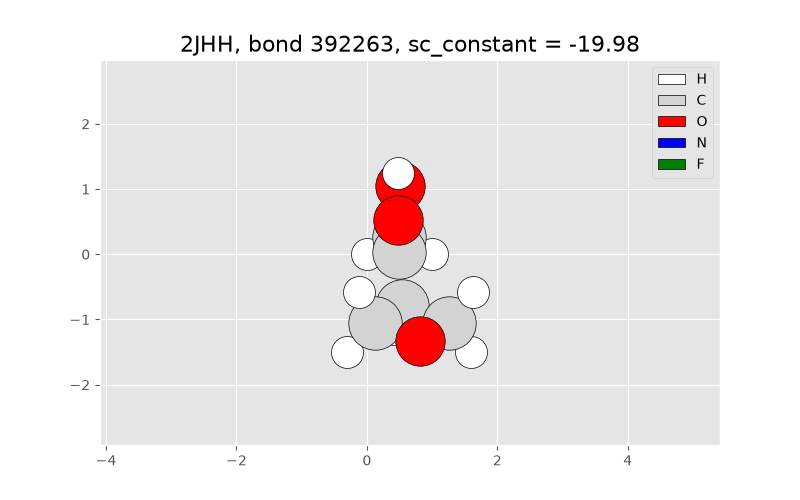

MovieWriter imagemagick unavailable; using Pillow instead.


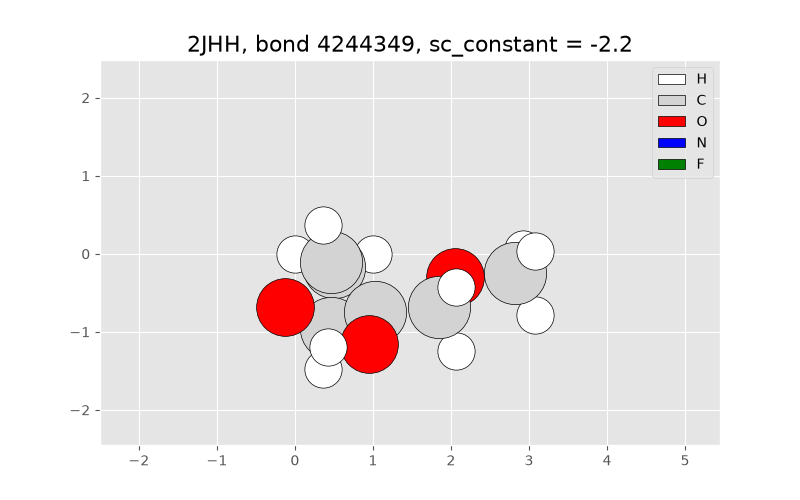

MovieWriter imagemagick unavailable; using Pillow instead.


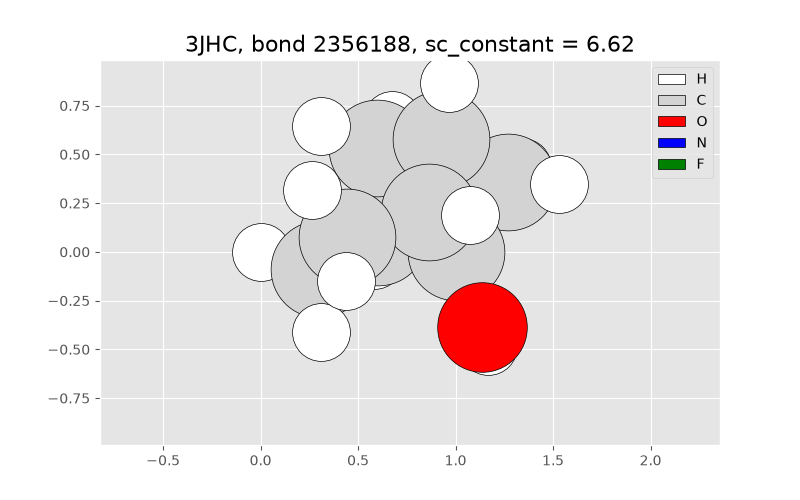

MovieWriter imagemagick unavailable; using Pillow instead.


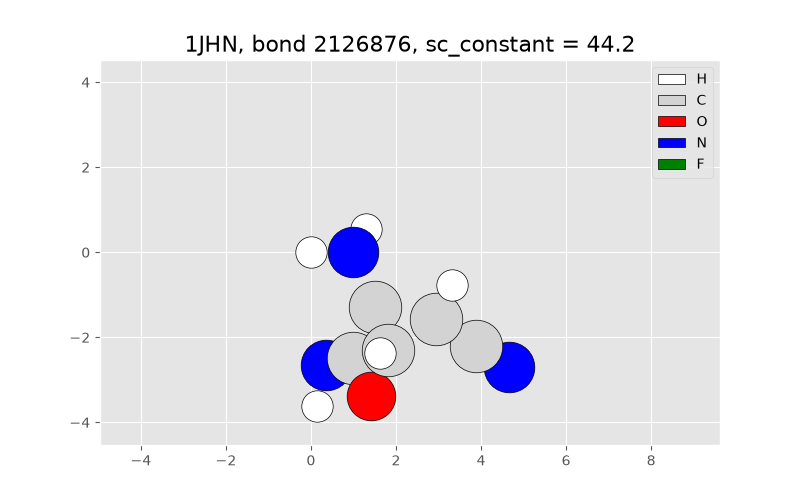

MovieWriter imagemagick unavailable; using Pillow instead.


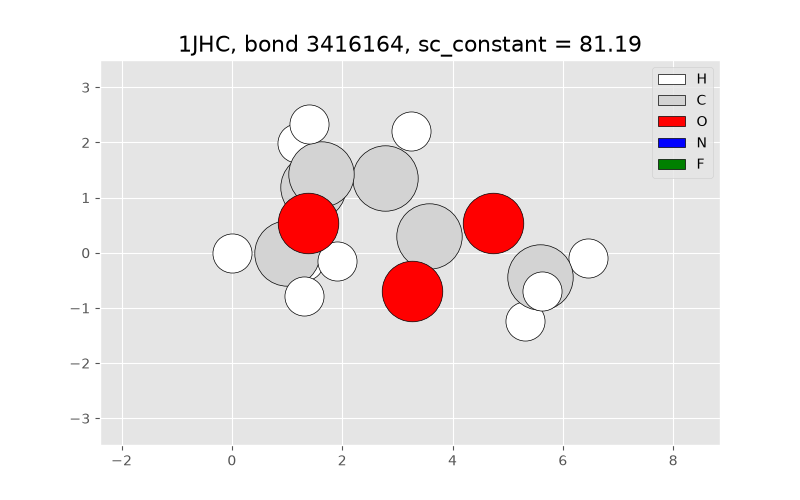

MovieWriter imagemagick unavailable; using Pillow instead.


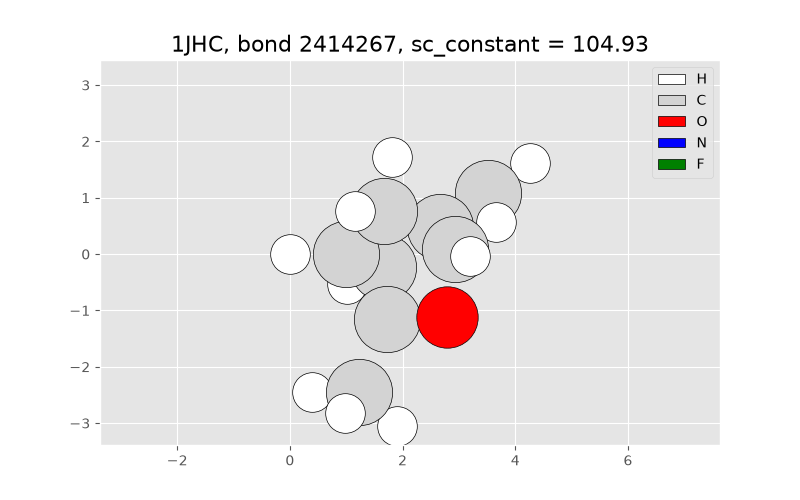

MovieWriter imagemagick unavailable; using Pillow instead.


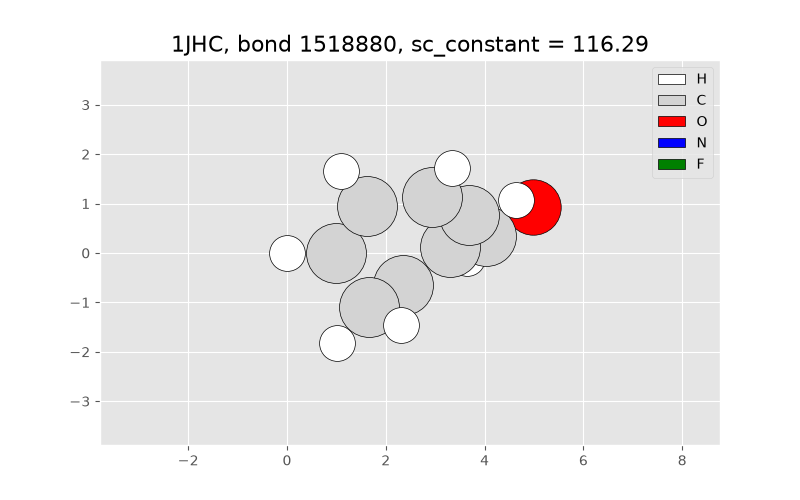

MovieWriter imagemagick unavailable; using Pillow instead.


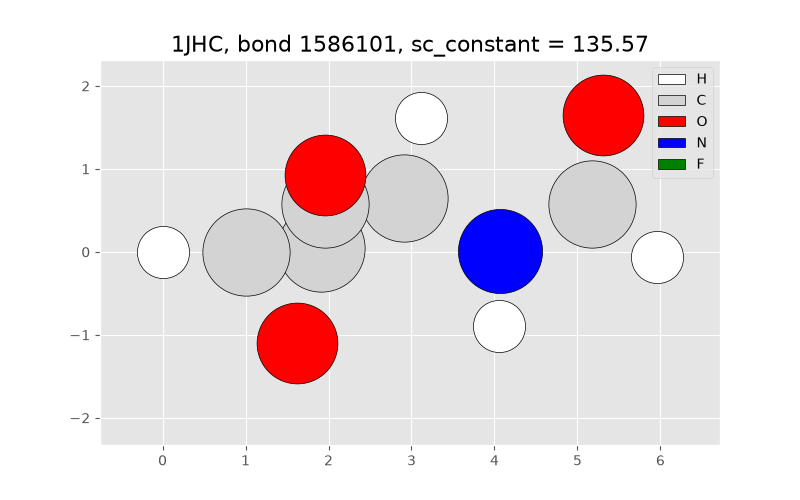

MovieWriter imagemagick unavailable; using Pillow instead.


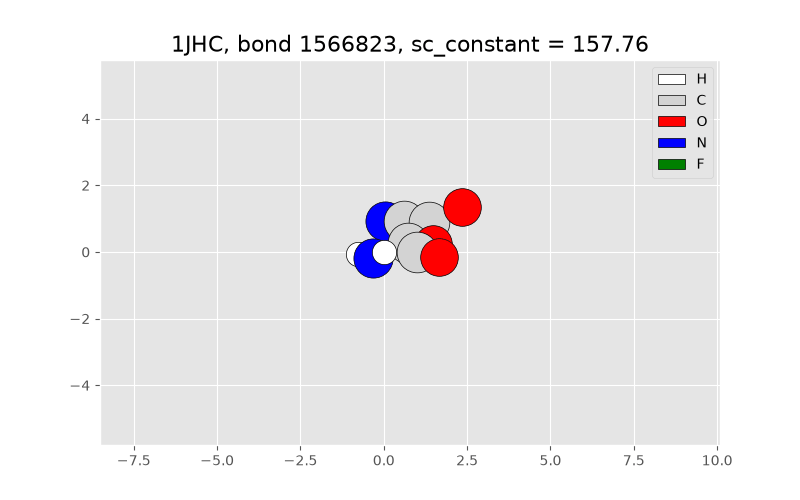

MovieWriter imagemagick unavailable; using Pillow instead.


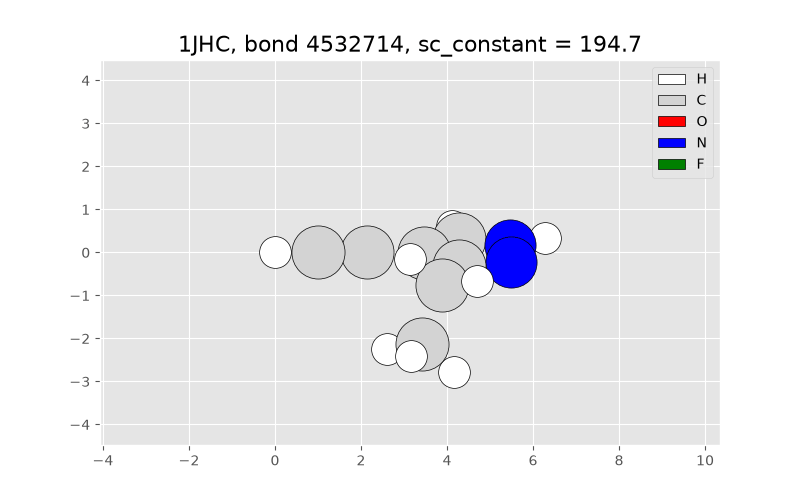

In [93]:
#we eparate the data into DIVS equal parts and take SAMPLES random samples from each part.
DIVS=10
SAMPLES=1
mn = train_df['scalar_coupling_constant'].min()
mx = train_df['scalar_coupling_constant'].max()
step = (mx - mn) / DIVS

samples_idx = [] 
for k in range(DIVS):
    lower = mn + k * step
    upper = mn + (k +1) * step
    samples = train_df[(train_df['scalar_coupling_constant'] >= lower) & (train_df['scalar_coupling_constant'] < upper)].sample(SAMPLES, random_state=50)
    samples_idx.append(samples.index.values[0])


np_xyz = structures[['x','y','z']].values.astype('float32')
#np_atoms = structures_df['atom'].values
mp = {'H':0,'C':1,'O':2,'N':3,'F':4}
np_atoms = structures['atom'].map(mp).values.astype('int8')
ss = structures.groupby('molecule_name').size()
ss = ss.cumsum()
ssx = np.zeros(len(ss) + 1, 'int')
ssx[1:] = ss; ssx[0] = 0
np_dict = {}
for k in range(len(ss)):
    np_dict[ss.index[k]] = k


def standardizer(mol_name, t1, t2, phi2=0, a_count=0):

    atom_df = np_atoms[ ssx[np_dict[mol_name]]:ssx[np_dict[mol_name]+1] ]
    mol_df = np_xyz[ ssx[np_dict[mol_name]]:ssx[np_dict[mol_name]+1], ].copy()
    mol_df -= mol_df[t1,]
    bond_dist = np.sqrt(mol_df[t2,].dot(mol_df[t2,])).astype('float32')
    mol_df /= bond_dist
    
    if mol_df[t2,0]==0: theta = np.sign(mol_df[t2,2])*np.pi/2
    else: theta = np.arctan(mol_df[t2,2]/mol_df[t2,0])
    M = np.array([[np.cos(-theta),-np.sin(-theta)],[np.sin(-theta),np.cos(-theta)]])
    mol_df[:,[0,2]] = (M.dot(mol_df[:,[0,2]].T)).T    
    
    if mol_df[t2,0]==0: phi = np.sign(mol_df[t2,1])*np.pi/2
    else: phi = np.arctan(mol_df[t2,1]/mol_df[t2,0])
    if mol_df[t2,0] < 0: phi += np.pi
    M = np.array([[np.cos(-phi),-np.sin(-phi)],[np.sin(-phi),np.cos(-phi)]])
    mol_df[:,[0,1]] = (M.dot(mol_df[:,[0,1]].T)).T         
      
    M = np.array([[np.cos(-phi2),-np.sin(-phi2)],[np.sin(-phi2),np.cos(-phi2)]])
    mol_df[:,[1,2]] = (M.dot(mol_df[:,[1,2]].T)).T 
            
    # CLOSEST NEIGHBORS TO ATOM_INDEX_1
    neighbor_types = [np.nan]*a_count
    neighbor_dists = [np.nan]*a_count
    if a_count>0:
        dst = np.sum( (mol_df-[1,0,0])*(mol_df-[1,0,0]), axis=1 )
        dst[t1] = 1e3; dst[t2] = 1e3
        idst = np.argsort(dst)
        ln = np.min((len(idst)-2,a_count))
        neighbor_types[:ln] = atom_df[idst[:ln]]
        neighbor_dists[:ln] = dst[idst[:ln]]
        
    return (atom_df, mol_df, bond_dist, neighbor_types, neighbor_dists)

def animate(j,title='',display_bonds=DISPLAY_BONDS):
    # CONSTANTS
    atoms = ['H','C','O','N','F']
    colors = ['white','lightgray','red','blue','green']
    sizes = [25, 70, 60, 65, 50]
    lkeys = []
    for k in range(5):
        lkeys.append(mpatches.Patch(facecolor=colors[k], label=atoms[k], edgecolor='black'))
    
    # EDA PLOTS
    mol_name = train_df.loc[j,'molecule_name']
    target_1 = train_df.loc[j,'atom_index_0']
    target_2 = train_df.loc[j,'atom_index_1']
    constant = train_df.loc[j,'scalar_coupling_constant']
    btype = train_df.loc[j,'type']
    frames = []; scl = 1.0
    fig = plt.figure(figsize=(8,5))
    for jj,alpha in enumerate(np.linspace(0,2*np.pi,16)):
        atom_df, mol_df, dis, _, _ = standardizer(mol_name, target_1, target_2, alpha)
        if jj==0: # SCALE CIRCLES IN PLOT
            mxx = np.sqrt(np.max( mol_df[:,1]**2 + mol_df[:,2]**2 ))
            if btype[0]=='2': mxx *= 1.5
            elif btype[0]=='3': mxx *= 2.0
            if mxx<0.1: scl = 200
            else: scl = 87.*(1+0.2*(4-mxx))/mxx
            if display_bonds: scl /= 3.
        # DISPLAY BONDS
        all = []
        if display_bonds:
            ds = mol_df[:,None,:]-mol_df
            dist = np.sqrt(np.einsum('ijk,ijk->ij',ds,ds))
            dist = (dist<1.65/dis).astype(np.int8)
            for k in range(len(mol_df)):
                for kk in range(k+1,len(mol_df)):
                    if dist[k,kk]==1:
                        pp, = plt.plot([mol_df[k,0],mol_df[kk,0]],[mol_df[k,1],mol_df[kk,1]],color='black', zorder=-1 )
                        all.append( pp )
        # ARRANGE ATOMS FROM BACK TO FRONT
        mol_df = np.concatenate([mol_df,atom_df.reshape((-1,1))],axis=1)
        midx = np.argsort(mol_df[:,2],axis=0)
        mol_df = mol_df[midx,]
        atom_df = mol_df[:,3].astype('int8')

        for k in range(len(mol_df)):
            all.append( plt.scatter(mol_df[k,0],mol_df[k,1],color=colors[atom_df[k]],edgecolor='black',s=scl*sizes[atom_df[k]]) )
        xlm = plt.xlim()
        plt.legend(handles=lkeys)
        pre = btype
        if title!='': pre = title
        plt.title(pre+', bond '+str(j)+', sc_constant = '+str(np.round(constant,2)),fontsize=16)
        plt.axis('equal')
        frames.append(all)
    # MAKE ANIMATION
    ani = ArtistAnimation(fig, frames)
    ani.save('data'+str(j)+'.gif', writer='imagemagick', fps=5)
    plt.close()
    #print('Bond',j,',Molecule',mol_name)
    with open('data'+str(j)+'.gif','rb') as file:
        display(Image(file.read()))
        
# DISPLAY OUR 10 SAMPLES
for j in samples_idx: animate(j)

## 1JHN Molecule Animations: Standardizing and Visualizing Molecular Geometry

In this step we explore how the 3D structure of a molecule relates to the `scalar_coupling_constant`, focusing on **1JHN** couplings (one H atom bonded directly to one N atom).

### 1. Sampling
We split the range of `scalar_coupling_constant` into `DIVS = 10` equal intervals and draw `SAMPLES = 1` random coupling from each one. This gives us 10 molecules, from the smallest to the largest coupling constant, so we can compare them visually.

### 2. Fast access to molecules (NumPy index)
To avoid filtering a huge DataFrame for every molecule:
- All coordinates are stored in one `float32` array (`np_xyz`) and atom types in one integer array (`np_atoms`: H=0, C=1, O=2, N=3, F=4).
- `ssx` stores the cumulative number of atoms, so molecule `k` is the slice `ssx[k]:ssx[k+1]`.
- `np_dict` maps `molecule_name` to its index `k`.

### 3. Standardizing the frame (`standardizer`)
Position and orientation in space do not affect the coupling constant, only the internal geometry (distances and angles) does. So for each H-N pair we:
1. **Translate** the molecule so the H atom is at (0, 0, 0).
2. **Scale** by the H-N bond length, so N sits at distance 1 (the original distance is saved as `bond_dist`).
3. **Rotate** twice (XZ plane, then XY plane) so that N lies at (1, 0, 0).
4. **Rotate** around the H-N axis by an optional angle `phi2` (used for the animation).

All molecules now share the same reference frame and can be compared directly. The function can also return the closest neighbors of the N atom (their types and distances).

### 4. Animation (`animate`)
For each sampled coupling we rotate the molecule 360° around the H-N axis (16 frames) and draw:
- atoms colored and sized by element (H white, C gray, O red, N blue, F green),
- bonds between atoms closer than 1.65 Å,
- atoms sorted from back to front so the 3D effect looks right.

The result is saved as a GIF.

### Observations
- N usually bonds with 3 atoms: the original H plus 2 others.
- If N has only one other neighbor, or if that neighbor is another H, the coupling constant is **small**.
- If N bonds with larger atoms (C or another N), the coupling constant is **large**.
- The H-N distance and the distances to the other two neighbors of N are useful features for a model gnn 

**found a features for reforcing my predictor model for that type of BONd 1j**


In [94]:

test_df



,id,molecule_name,atom_index_0,atom_index_1,type
0,4659076,dsgdb9nsd_000004,2,0,2JHC
1,4659077,dsgdb9nsd_000004,2,1,1JHC
2,4659078,dsgdb9nsd_000004,2,3,3JHH
3,4659079,dsgdb9nsd_000004,3,0,1JHC
4,4659080,dsgdb9nsd_000004,3,1,2JHC
...,...,...,...,...,...
2505185,7164261,dsgdb9nsd_133885,15,3,2JHC
2505186,7164262,dsgdb9nsd_133885,15,4,2JHC
2505187,7164263,dsgdb9nsd_133885,15,6,3JHC
2505188,7164264,dsgdb9nsd_133885,15,7,2JHC


In [95]:
def build_summary(df : pd.DataFrame) -> pd.DataFrame:
    rows = []
    for column in df.columns:
        rows.append({
            'Column Name': column
             , 'Data Type': df[column].dtype
            , 'Missing Values': df[column].isnull().sum() , 
            'missing pct ' : df[column].isnull().sum() / len(df) * 100 , 
            'nunique': int(df[column].nunique()),
                      'sample_values': ','.join(df[column].dropna().astype(str).unique()[:4]),
                  })




    return pd.DataFrame(rows)


In [96]:
TARGET = ['scalar_coupling_constant']

eda_cols = [c for c in train_df.columns if c not in TARGET ]
eda_summary = build_summary(train_df[eda_cols])
print(eda_summary)
     


     Column Name Data Type  Missing Values  missing pct   nunique  \
0             id     int64               0           0.0  4659076   
1  molecule_name    object               0           0.0    85012   
2   atom_index_0     int64               0           0.0       28   
3   atom_index_1     int64               0           0.0       29   
4           type    object               0           0.0        8   

                                       sample_values  
0                                            0,1,2,3  
1  dsgdb9nsd_000001,dsgdb9nsd_000002,dsgdb9nsd_00...  
2                                            1,2,3,4  
3                                            0,2,3,4  
4                                1JHC,2JHH,1JHN,2JHN  


In [97]:
eda_cols_test = [c for c in test_df.columns]
eda_summary_test = build_summary(test_df[eda_cols_test])
print(eda_summary_test)



     Column Name Data Type  Missing Values  missing pct   nunique  \
0             id     int64               0           0.0  2505190   
1  molecule_name    object               0           0.0    45777   
2   atom_index_0     int64               0           0.0       29   
3   atom_index_1     int64               0           0.0       29   
4           type    object               0           0.0        8   

                                       sample_values  
0                    4659076,4659077,4659078,4659079  
1  dsgdb9nsd_000004,dsgdb9nsd_000014,dsgdb9nsd_00...  
2                                            2,3,4,5  
3                                            0,1,3,4  
4                                2JHC,1JHC,3JHH,2JHH  


In [98]:
df_scalar_coupling_contributions = pd.read_csv(os.path.join(DATA_DIR, 'scalar_coupling_contributions.csv'))

df_scalar_coupling_contributions.head(3)

,molecule_name,atom_index_0,atom_index_1,type,fc,sd,pso,dso
0,dsgdb9nsd_000001,1,0,1JHC,83.0224,0.254579,1.25862,0.27201
1,dsgdb9nsd_000001,1,2,2JHH,-11.0347,0.352978,2.85839,-3.43360
2,dsgdb9nsd_000001,1,3,2JHH,-11.0325,0.352944,2.85852,-3.43387


In [99]:
test_features = pd.concat([df_scalar_coupling_contributions, test_df], ignore_index=True)
test_features 

,molecule_name,atom_index_0,atom_index_1,type,fc,sd,pso,dso,id
0,dsgdb9nsd_000001,1,0,1JHC,83.0224,0.254579,1.25862,0.272010,NaN
1,dsgdb9nsd_000001,1,2,2JHH,-11.0347,0.352978,2.85839,-3.433600,NaN
2,dsgdb9nsd_000001,1,3,2JHH,-11.0325,0.352944,2.85852,-3.433870,NaN
3,dsgdb9nsd_000001,1,4,2JHH,-11.0319,0.352934,2.85855,-3.433930,NaN
4,dsgdb9nsd_000001,2,0,1JHC,83.0222,0.254585,1.25861,0.272013,NaN
...,...,...,...,...,...,...,...,...,...
7164261,dsgdb9nsd_133885,15,3,2JHC,NaN,NaN,NaN,NaN,7164261.0
7164262,dsgdb9nsd_133885,15,4,2JHC,NaN,NaN,NaN,NaN,7164262.0
7164263,dsgdb9nsd_133885,15,6,3JHC,NaN,NaN,NaN,NaN,7164263.0
7164264,dsgdb9nsd_133885,15,7,2JHC,NaN,NaN,NaN,NaN,7164264.0


In [100]:
test_features.to_csv(r"C:\Users\pc\Downloads\champs-scalar-coupling\test_features.csv", index=False)

In [101]:
test_features.drop(columns= ['id'] )



,molecule_name,atom_index_0,atom_index_1,type,fc,sd,pso,dso
0,dsgdb9nsd_000001,1,0,1JHC,83.0224,0.254579,1.25862,0.272010
1,dsgdb9nsd_000001,1,2,2JHH,-11.0347,0.352978,2.85839,-3.433600
2,dsgdb9nsd_000001,1,3,2JHH,-11.0325,0.352944,2.85852,-3.433870
3,dsgdb9nsd_000001,1,4,2JHH,-11.0319,0.352934,2.85855,-3.433930
4,dsgdb9nsd_000001,2,0,1JHC,83.0222,0.254585,1.25861,0.272013
...,...,...,...,...,...,...,...,...
7164261,dsgdb9nsd_133885,15,3,2JHC,NaN,NaN,NaN,NaN
7164262,dsgdb9nsd_133885,15,4,2JHC,NaN,NaN,NaN,NaN
7164263,dsgdb9nsd_133885,15,6,3JHC,NaN,NaN,NaN,NaN
7164264,dsgdb9nsd_133885,15,7,2JHC,NaN,NaN,NaN,NaN


In [102]:
eda_cols_test_feature = [c for c in test_features.columns]
eda_summary_test = build_summary(test_features[eda_cols_test_feature])
print(eda_summary_test)




     Column Name Data Type  Missing Values  missing pct   nunique  \
0  molecule_name    object               0      0.000000   130789   
1   atom_index_0     int64               0      0.000000       29   
2   atom_index_1     int64               0      0.000000       29   
3           type    object               0      0.000000        8   
4             fc   float64         2505190     34.967853  2170719   
5             sd   float64         2505190     34.967853   577108   
6            pso   float64         2505190     34.967853  1356440   
7            dso   float64         2505190     34.967853  1443358   
8             id   float64         4659076     65.032147  2505190   

                                       sample_values  
0  dsgdb9nsd_000001,dsgdb9nsd_000002,dsgdb9nsd_00...  
1                                            1,2,3,4  
2                                            0,2,3,4  
3                                1JHC,2JHH,1JHN,2JHN  
4                 83.0224,-11.0347

In [103]:
yellow, cyan_g, cyan_dark = "#F7C53E", "#0CF7AF", "#11AB7C"
purple, purple_dark, purple_light = "#D826F8", "#9309AB", "#b683d6"
blue, red, orange, green = "#0C97FA", "#FA1D19", "#FA9F19", "#0CFA58"
light_blue, soft_blue, dark_blue = "#01FADC", "#81c9e6", "#394be6"


PALETTE_2 = [cyan_g, purple]
PALETTE_3 = [yellow, cyan_g, purple]
PALETTE_7 = [purple_dark, purple_light, purple, blue, light_blue, dark_blue, soft_blue]